# 02 · Baselines

Before building a neural network we need a number to beat. Two baselines:

1. **Lazy model**: always predicts "legit". It shows why accuracy is the wrong metric.
2. **Logistic regression**: the simplest real model. Every later model has to beat its PR-AUC on the cv set.

In [16]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))  # make `src` importable from notebooks/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIGURES = Path("../reports/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

# Fixed colors: blue is always "legit", orange is always "fraud".
LEGIT, FRAUD = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=[LEGIT, FRAUD, "#1baf7a", "#eda100"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "figure.dpi": 110,
})

In [17]:
from src.data import load_raw, split_by_time
from src.evaluate import confusion, evaluate, plot_pr_curves, results_table
from src.features import Preprocessor
from src.train import train_lazy, train_logistic

## Split first, then preprocess

The split happens on the raw data. The `Preprocessor` is fitted on train only and then applied to cv; the test set stays untouched until the very end of the project.

In [18]:
split = split_by_time(load_raw())
split.summary()

,rows,frauds,fraud_rate_%
train,170884.0,360.0,0.210669
cv,56961.0,57.0,0.100068
test,56962.0,75.0,0.131667


Note how the fraud rate changes between parts: 0.21% in train, 0.10% in cv. That is the drift seen in the EDA. Also, cv holds only ~57 frauds, so each one moves recall by almost 2 points. Small differences between models can be noise.

In [19]:
prep = Preprocessor().fit(split.train)
X_train, y_train = prep.transform(split.train)
X_cv, y_cv = prep.transform(split.cv)
X_train.shape, X_cv.shape

((170884, 30), (56961, 30))

## Train and evaluate

In [20]:
models = {
    "lazy": train_lazy(X_train, y_train),
    "logistic": train_logistic(X_train, y_train),
}
probs = {name: m.predict_proba(X_cv)[:, 1] for name, m in models.items()}
results = {name: evaluate(y_cv, p) for name, p in probs.items()}
results_table(results)

,accuracy,precision,recall,f1,pr_auc,roc_auc
logistic,0.9992,0.6429,0.4737,0.5455,0.6287,0.9687
lazy,0.9990,0.0000,0.0000,0.0000,0.0010,0.5000


The lazy model has 99.9% accuracy and catches **zero** frauds. Logistic regression has practically the same accuracy, yet it catches about half of them. Accuracy cannot tell these two models apart; recall and PR-AUC can.

In [21]:
confusion(y_cv, probs["logistic"])

,pred: legit,pred: fraud
actual: legit,56889,15
actual: fraud,30,27


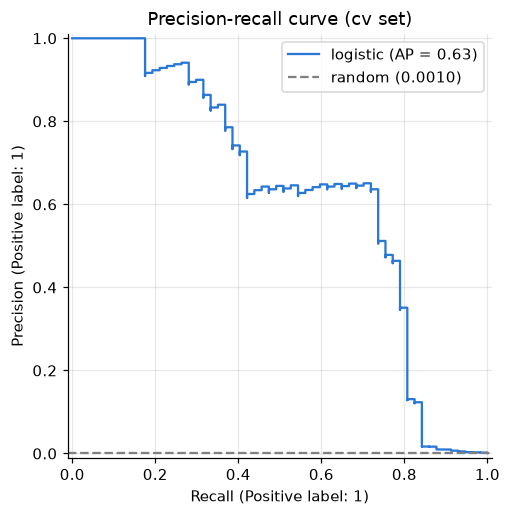

In [22]:
ax = plot_pr_curves(y_cv, {"logistic": probs["logistic"]})
ax.figure.savefig(FIGURES / "pr_curve_baselines.png", bbox_inches="tight")

## Does class weighting help?

Logistic regression minimizes average log loss, and with 99.8% legit rows the cheapest strategy is to lean towards "legit". `class_weight="balanced"` makes each fraud count as much as ~500 legit rows.

In [23]:
weighted = train_logistic(X_train, y_train, class_weight="balanced")
probs["logistic (balanced)"] = weighted.predict_proba(X_cv)[:, 1]
results["logistic (balanced)"] = evaluate(y_cv, probs["logistic (balanced)"])
results_table(results)

,accuracy,precision,recall,f1,pr_auc,roc_auc
logistic (balanced),0.9611,0.0226,0.8947,0.0440,0.7616,0.9721
logistic,0.9992,0.6429,0.4737,0.5455,0.6287,0.9687
lazy,0.9990,0.0000,0.0000,0.0000,0.0010,0.5000


In [24]:
confusion(y_cv, probs["logistic (balanced)"])

,pred: legit,pred: fraud
actual: legit,54695,2209
actual: fraud,6,51


Two effects show up at once:

- **At the 0.5 threshold**, weighting trades precision for recall: almost every fraud is caught, but there are thousands of false alarms. That is a threshold problem, and the threshold will be chosen later by cost (step 6 of the project).
- **PR-AUC goes up as well**, and PR-AUC does not depend on the threshold. So weighting did more than shift the probabilities: it changed which transactions the model ranks as most suspicious, for the better. Without weights, the fraud examples contribute so little to the average loss that gradient descent mostly ignores them.

**Baseline to beat: the balanced logistic regression PR-AUC on cv.**